# L2: Text classification

Text classification is the task of sorting text documents into predefined classes. The concrete problem you will be working on in this lab is the classification of texts with respect to their political affiliation. The specific texts you are going to classify are speeches held in the [Riksdag](https://www.riksdagen.se/en/), the Swedish national legislature.

**Before starting with this lab, here is a quick reminder about our [Rules for hand-in assignments](https://www.ida.liu.se/~TDDE16/exam.en.shtml#handins) and the [Policy on cheating and plagiarism](https://www.ida.liu.se/~TDDE16/exam.en.shtml#cheating).**

## Data set

The raw data for this lab comes from [The Riksdag’s Open Data](https://data.riksdagen.se/in-english/). We have tokenized the speeches and put them into two compressed [JSON](https://en.wikipedia.org/wiki/JSON) files:

* `speeches-201718.json.bz2` (speeches from the 2017/2018 parliamentary session)
* `speeches-201819.json.bz2` (ditto, from the 2018/2019 session)

We start by loading these files into two separate data frames.

In [8]:
import pandas as pd
import bz2

with bz2.open('speeches-201718.json.bz2') as source:
    speeches_201718 = pd.read_json(source)

with bz2.open('speeches-201819.json.bz2') as source:
    speeches_201819 = pd.read_json(source)

When you inspect the two data frames, you can see that there are three labelled columns: `id` (the official speech ID), `words` (the space-separated words of the speech), and `party` (the party of the speaker, represented by its customary abbreviation).

In [9]:
speeches_201718.head()

,id,words,party
0,H5-002-004,eders majestäter eders kungliga högheter herr ...,S
1,H5-003-001,aktuell debatt om situationen för ensamkommand...,V
2,H5-003-002,herr talman och ledamöter jag vill börja med a...,S
3,H5-003-003,herr talman åhörare den här debatten handlar a...,M
4,H5-003-004,herr talman ansvar och rättssäkerhet är två or...,SD


Throughout the lab, we will be using the speeches from 2017/2018 as our training data, and the speeches from 2018/2019 as our test data.

In [10]:
training_data, test_data = speeches_201718, speeches_201819

For later reference, we store the sorted list of party abbreviations.

In [11]:
parties = sorted(training_data['party'].unique())
print(parties)

['C', 'KD', 'L', 'M', 'MP', 'S', 'SD', 'V']


## Problem 1: Visualization

Your first task is to get to know the data better by producing a simple visualization.

If you are not familiar with the Swedish political system and the parties represented in the Riksdag in particular, then we suggest that you have a look at the Wikipedia article about the [2018 Swedish general election](https://en.wikipedia.org/wiki/2018_Swedish_general_election).

For the lab, we ask you to compare the two data frames with respect to the distribution of the speeches over the different parties. Write code to generate two bar plots that visualize this information, one for the 2017/2018 speeches and one for the 2018/2019 speeches. Inspect the two plots, and compare them

* to each other
* to the results of the 2014 and the 2018 general elections

Summarize your observations in a short text in the cell below.

**Tip:** If you need help with creating bar plots, [Bar Plot using Pandas](https://dfrieds.com/data-visualizations/bar-plot-python-pandas) provides a useful tutorial.

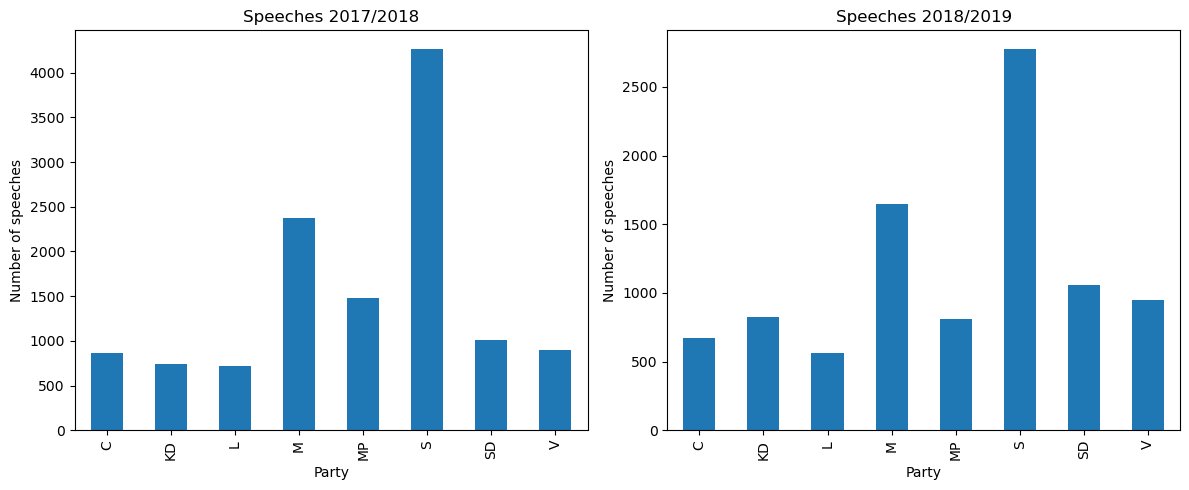

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

training_data["party"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], title="Speeches 2017/2018"
)
axes[0].set_xlabel("Party")
axes[0].set_ylabel("Number of speeches")

test_data["party"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1], title="Speeches 2018/2019"
)
axes[1].set_xlabel("Party")
axes[1].set_ylabel("Number of speeches")

plt.tight_layout()
plt.show()

***The two plots show that the distribution of speeches is clearly imbalanced. The Social Democrats (S) have the largest number of speeches in both sessions, followed by the Moderates (M). The other parties have substantially fewer speeches. The overall pattern is similar between the two parliamentary sessions, although the exact number of speeches changes. The speech distribution should not be interpreted as exactly the same as the election result, because the plots count parliamentary speeches rather than votes or seats. The imbalance is important because a classifier can perform well on frequent parties while performing poorly on smaller parties.***

## Problem 2: Naive Bayes classifier

You are now ready to train and evaluate a classifier. More specifically, we ask you to train a [Multinomial Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html#multinomial-naive-bayes) classifier. You will have to

1. vectorize the speeches in the training data
2. instantiate and fit the Naive Bayes model
3. evaluate the model on the test data

The scikit-learn library provides a convenience class [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) that allows you to solve the first two tasks with very compact code. For the evaluation you can use the function [`classification_report`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html), which will report per-class precision, recall and F1, as well as overall accuracy.

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

nb_pipeline = Pipeline([
    ("vectorizer", CountVectorizer()),
    ("classifier", MultinomialNB())
])

nb_pipeline.fit(training_data["words"], training_data["party"])
predictions = nb_pipeline.predict(test_data["words"])

print(classification_report(test_data["party"], predictions))

              precision    recall  f1-score   support

           C       0.63      0.04      0.07       671
          KD       0.70      0.02      0.03       821
           L       0.92      0.02      0.04       560
           M       0.36      0.68      0.47      1644
          MP       0.36      0.25      0.29       809
           S       0.46      0.84      0.59      2773
          SD       0.57      0.12      0.20      1060
           V       0.59      0.15      0.24       950

    accuracy                           0.43      9288
   macro avg       0.57      0.26      0.24      9288
weighted avg       0.52      0.43      0.34      9288



Would you have expected the results that you got?

***Yes, I would have expected these results. Naive Bayes can classify political speeches better than a random or most-frequent baseline because different parties tend to use different words and topics. However, I would not expect very high accuracy because political parties can discuss many of the same topics and use similar vocabulary. The imbalanced distribution of speeches also explains why the model performs better for the larger parties than for some smaller parties.***

## Problem 3: Baselines

Evaluation metrics such as accuracy should not be understood as absolute measures of performance, but should be used only to compare different classifiers. When other classifiers are not available, a simple baseline is a classifier that generates predictions by random sampling, respecting the training set&rsquo;s class distribution. This baseline is implemented by the class [DummyClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html). What is the performance of the random baseline on the test data?

In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

random_baseline = DummyClassifier(strategy="stratified", random_state=42)
random_baseline.fit(training_data["words"], training_data["party"])

random_predictions = random_baseline.predict(test_data["words"])
print("Random baseline accuracy:", accuracy_score(test_data["party"], random_predictions))

Random baseline accuracy: 0.1700043066322136


An even dumber baseline is to predict, for every document, that class which appears most often in the training data. This baseline is also called the most frequent class baseline. What is the accuracy of that baseline on the test data?

In [15]:
most_frequent_baseline = DummyClassifier(strategy="most_frequent")
most_frequent_baseline.fit(training_data["words"], training_data["party"])

most_frequent_predictions = most_frequent_baseline.predict(test_data["words"])
print("Most frequent baseline accuracy:",
      accuracy_score(test_data["party"], most_frequent_predictions))

Most frequent baseline accuracy: 0.298557278208441


## Problem 4: Creating a balanced data set

As you saw in Problem&nbsp;1, the distribution of the speeches over the eight different parties (classes) is imbalanced. One technique used to alleviate this is **undersampling**, in which one randomly removes samples from over-represented classes until all classes are represented with the same number of samples.

Implement undersampling to create a balanced subset of the training data. Rerun the evaluation from Problem&nbsp;2 on the balanced data and compare the results. Summarise your results in a short text.

**Hint:** Your balanced subset should consist of 5,752 speeches.

In [16]:
# Undersampling: keep the same number of speeches for every party.
# The smallest class in the training set contains 719 speeches, so the balanced data set contains 8 * 719 = 5,752 speeches.

balanced_training_data = (
    training_data.groupby("party", group_keys=False)
    .sample(n=training_data["party"].value_counts().min(), random_state=42)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

print(balanced_training_data["party"].value_counts().sort_index())
print("Number of speeches:", len(balanced_training_data))

balanced_pipeline = Pipeline([
    ("vectorizer", CountVectorizer()),
    ("classifier", MultinomialNB())
])

balanced_pipeline.fit(
    balanced_training_data["words"],
    balanced_training_data["party"]
)

balanced_predictions = balanced_pipeline.predict(test_data["words"])
print(classification_report(test_data["party"], balanced_predictions))

party
C     719
KD    719
L     719
M     719
MP    719
S     719
SD    719
V     719
Name: count, dtype: int64
Number of speeches: 5752
              precision    recall  f1-score   support

           C       0.28      0.47      0.35       671
          KD       0.29      0.40      0.33       821
           L       0.27      0.45      0.33       560
           M       0.43      0.44      0.44      1644
          MP       0.34      0.41      0.37       809
           S       0.79      0.34      0.48      2773
          SD       0.45      0.39      0.42      1060
           V       0.39      0.54      0.46       950

    accuracy                           0.41      9288
   macro avg       0.40      0.43      0.40      9288
weighted avg       0.50      0.41      0.42      9288



*TODO: Enter the summary of your results here*


***Undersampling reduces the training set from 12,343 to 5,752 speeches by keeping 719 speeches for each party. The ordinary Naive Bayes model achieved about 42.8% accuracy, while the balanced version achieved about 41.1% accuracy on the same test set. Thus, undersampling slightly reduced overall accuracy, but the class-level results became more balanced: smaller parties generally received much higher recall, while recall for the large S class decreased. This shows why accuracy alone is not enough for an imbalanced classification problem.***

## Problem 5: Confusion matrix

A **confusion matrix** is a specific table that is useful when analysing the performance of a classifier. In this table, both the rows and the columns correspond to classes, and each cell $(i, j)$ states how many times a sample with gold-standard class $i$ was predicted as belonging to class $j$.

In scitkit-learn, the confusion matrix of a classifier is computed by the function [`confusion_matrix`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html). If you would rather see a visual representation, you can also use [`plot_confusion_matrix`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.plot_confusion_matrix.html).

Your task is to use the confusion matrix in order to find, for each given party $p$ in the Riksdag, that other party $p'$ which the classifier that you trained in Problem&nbsp;4 most often confuses with $p$ when it predicts the party of a speaker.

In [17]:
from sklearn.metrics import confusion_matrix
import numpy as np

labels = sorted(training_data["party"].unique())
cm = confusion_matrix(
    test_data["party"],
    balanced_predictions,
    labels=labels
)

print("Confusion matrix (rows = true party, columns = predicted party):")
print(pd.DataFrame(cm, index=labels, columns=labels))

print("\nMost common confusion for each party:")
for i, party in enumerate(labels):
    row = cm[i].copy()
    row[i] = -1  # ignore correct predictions
    confused_with = labels[np.argmax(row)]
    print(f"{party} -> {confused_with}: {cm[i, np.argmax(row)]}")

Confusion matrix (rows = true party, columns = predicted party):
      C   KD    L    M   MP    S   SD    V
C   318   67   45   91   40   21   36   53
KD   82  325   53  160   47   30   55   69
L    62   50  251   53   31   15   36   62
M   205  196  155  722   93   66  114   93
MP   72   59   73   77  331   74   43   80
S   234  234  183  316  358  944  164  340
SD  116  110  118  141   39   26  412   98
V    66   80   63  104   42   16   65  514

Most common confusion for each party:
C -> M: 91
KD -> M: 160
L -> C: 62
M -> C: 205
MP -> V: 80
S -> MP: 358
SD -> M: 141
V -> M: 104


Take a minute to reflect on whether your results make sense.

 ***The confusion matrix shows that some parties are more often confused with other parties, especially parties that have similar political positions or discuss similar topics. It is also reasonable that smaller parties have fewer correct predictions because there are fewer training examples for them. Overall, the confusion matrix confirms that the model has difficulty separating some politically similar parties.***

## Problem 6: Grid search

Until now, you have been using the vectorizer and the Naive Bayes classifier with their default hyperparameters. When working with real-world applications, you would want to find settings for the hyperparameters that maximize the performance for the task at hand.

Manually tweaking the hyperparameters of the various components of a vectorizer–classifier pipeline can be cumbersome. However, scikit-learn makes it possible to run an exhaustive search for the best hyperparameters over a grid of possible values. This method is known as **grid search**.

The hyperparameters of a pipeline should never be tuned on the final test set. Instead, one should either use a separate validation set, or run cross-validation over different folds. Here we will use cross-validation.

Implement a grid search with 5-fold cross-validation to find the optimal parameters in a grid defined by the following choices for the hyperparameters:

* In the vectorizer, try a set-of-words (binary) model in addition to the default bag-of-words model (two possible parameter values).
* Also in the vectorizer, try extracting bigrams in addition to unigrams (two possible parameter values).
* In the Naive Bayes classifier, try using additive smoothing with $\alpha \in \{1, 0{.}1\}$ (two possible parameter values).

Use the class [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) from the scikit-learn library. Print the results of your best model, along with the parameter values that yielded these results.

In [18]:
from sklearn.model_selection import GridSearchCV

grid_pipeline = Pipeline([
    ("vectorizer", CountVectorizer()),
    ("classifier", MultinomialNB())
])

param_grid = {
    "vectorizer__binary": [False, True],
    "vectorizer__ngram_range": [(1, 1), (1, 2)],
    "classifier__alpha": [1, 0.1]
}

grid_search = GridSearchCV(
    grid_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(training_data["words"], training_data["party"])

print("Best parameters:")
print(grid_search.best_params_)
print("\nBest 5-fold CV accuracy:", grid_search.best_score_)

best_grid_predictions = grid_search.predict(test_data["words"])
print("\nPerformance on the test data:")
print(classification_report(test_data["party"], best_grid_predictions))

Best parameters:
{'classifier__alpha': 0.1, 'vectorizer__binary': False, 'vectorizer__ngram_range': (1, 1)}

Best 5-fold CV accuracy: 0.5859950583343673

Performance on the test data:
              precision    recall  f1-score   support

           C       0.39      0.27      0.32       671
          KD       0.45      0.24      0.31       821
           L       0.37      0.26      0.30       560
           M       0.44      0.58      0.50      1644
          MP       0.32      0.46      0.38       809
           S       0.61      0.65      0.63      2773
          SD       0.49      0.43      0.45      1060
           V       0.50      0.42      0.46       950

    accuracy                           0.48      9288
   macro avg       0.45      0.41      0.42      9288
weighted avg       0.48      0.48      0.48      9288



## Problem 7: Try to improve your results

Scikit-learn makes it easy to test different vectorizer–classifier pipelines – among other things, it includes different types of logistic regression classifiers, support vector machines, and decision trees. Browse the library to see which methods are supported.

Build a pipeline that you find interesting, and use grid search to find optimal settings for the hyperparameters. Print the results of your best model.

In [23]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import GridSearchCV

svm_pipeline = Pipeline([
    ("vectorizer", CountVectorizer()),
    ("classifier", LinearSVC())
])

svm_param_grid = {
    "vectorizer__binary": [False, True],
    "vectorizer__ngram_range": [(1, 1), (1, 2)],
    "classifier__C": [0.1, 1]
}

svm_grid = GridSearchCV(
    svm_pipeline,
    param_grid=svm_param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

svm_grid.fit(training_data["words"], training_data["party"])

print("Best SVM parameters:")
print(svm_grid.best_params_)

print("Best CV accuracy:", svm_grid.best_score_)

svm_predictions = svm_grid.predict(test_data["words"])

print("\nPerformance on the test data:")
print(classification_report(
    test_data["party"],
    svm_predictions
))

C:\Users\user\anaconda3\Lib\site-packages\sklearn\svm\_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Best SVM parameters:
{'classifier__C': 0.1, 'vectorizer__binary': False, 'vectorizer__ngram_range': (1, 2)}
Best CV accuracy: 0.588673041091154

Performance on the test data:
              precision    recall  f1-score   support

           C       0.44      0.33      0.37       671
          KD       0.51      0.21      0.29       821
           L       0.40      0.26      0.31       560
           M       0.50      0.54      0.52      1644
          MP       0.31      0.40      0.35       809
           S       0.55      0.78      0.64      2773
          SD       0.55      0.42      0.47      1060
           V       0.58      0.32      0.41       950

    accuracy                           0.50      9288
   macro avg       0.48      0.40      0.42      9288
weighted avg       0.50      0.50      0.48      9288



## Reflection questions

The following reflection questions will help you prepare for the diagnostic test. Answer each of them in the form of a short text and put your answers in the cell below. You will get feedback on your answers from your lab assistant.

**RQ 2.1:** Summarise the results of your experiments for Problem&nbsp;2. Are your results ‘good’ or ‘bad’? How do you determine that?

**RQ 2.2:** Summarise the results of your experiments for Problem&nbsp;4. Would you think that your results are typical even for other classification tasks? How would *oversampling* have looked like for this task? When would you use undersampling, when oversampling?

**RQ 2.3:** Which model performed best in your experiments for Problem&nbsp;6? Why is it important to do a hyperparameter search before drawing conclusions about the performance of a model? Why is it often not done, anyway? Why should you never tune hyperparameters on the test set?

***RQ 2.1:*** *The ordinary Multinomial Naive Bayes classifier achieved about 42.8% accuracy. This is better than both simple baselines: the random stratified baseline was about 17.0%, while the most-frequent baseline was about 29.9%. Therefore, the classifier is useful compared with the baselines, but the result is not uniformly good across all parties: recall is high for frequent parties such as S and M and very low for several smaller parties. I would therefore judge the model using accuracy together with precision, recall and F1, not accuracy alone.*

***RQ 2.2:*** *After undersampling, the training set contained 5,752 speeches, with 719 speeches per party. Accuracy decreased from about 42.8% to about 41.1%, but the classifier became less dominated by the largest classes and recall for smaller parties improved. This is a common effect of undersampling on imbalanced classification tasks, although the exact result depends on the data. Oversampling would instead duplicate or otherwise increase examples from under-represented classes until the classes are balanced. Undersampling is useful when the majority class has many redundant examples and the data set is large. Oversampling is useful when the data set is small and we do not want to discard majority-class examples.*

***RQ 2.3:*** *In Problem 6, the best 5-fold cross-validation configuration among the required choices was a binary set-of-words model with unigrams and bigrams, using Naive Bayes smoothing alpha = 0.1. Its mean cross-validation accuracy was about 61.3%. Hyperparameter search is important because the default settings are not necessarily appropriate for the task, and different settings can change performance substantially. It is often not done because exhaustive searches can be computationally expensive and take time. Hyperparameters must not be tuned on the final test set because then the test set influences model selection, making the reported test performance overly optimistic and no longer a fair estimate of generalization.*

**Congratulations on finishing L2! 👍**